# Practical 10 - PCA

Working on the wine dataset (178 wines, 13 chemical measurements, 3 wine classes). The target column here is called `target` (the wine class 0, 1 or 2).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = load_wine(as_frame=True)
df = wine.data.copy()
df["target"] = wine.target

features = list(wine.feature_names)
target_col = "target"

print("Shape:", df.shape)
df.head()

Shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


### 1. Basic statistics using describe()

In [2]:
print(df[features].describe().round(2))

print("1. describe() gives count, mean, std, min, quartiles and max for every feature.")
print("2. There are 178 rows for every feature, so there are no missing values.")
print("3. The scales are very different: proline goes from 278 to 1680, while hue is only between 0.48 and 1.71.")
print("4. Because of this difference in scale, the features need to be scaled before PCA.")

       alcohol  malic_acid     ash  alcalinity_of_ash  magnesium  \
count   178.00      178.00  178.00             178.00     178.00   
mean     13.00        2.34    2.37              19.49      99.74   
std       0.81        1.12    0.27               3.34      14.28   
min      11.03        0.74    1.36              10.60      70.00   
25%      12.36        1.60    2.21              17.20      88.00   
50%      13.05        1.87    2.36              19.50      98.00   
75%      13.68        3.08    2.56              21.50     107.00   
max      14.83        5.80    3.23              30.00     162.00   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count         178.00      178.00                178.00           178.00   
mean            2.30        2.03                  0.36             1.59   
std             0.63        1.00                  0.12             0.57   
min             0.98        0.34                  0.13             0.41   
25%         

### 2. Boxplot by output labels/classes

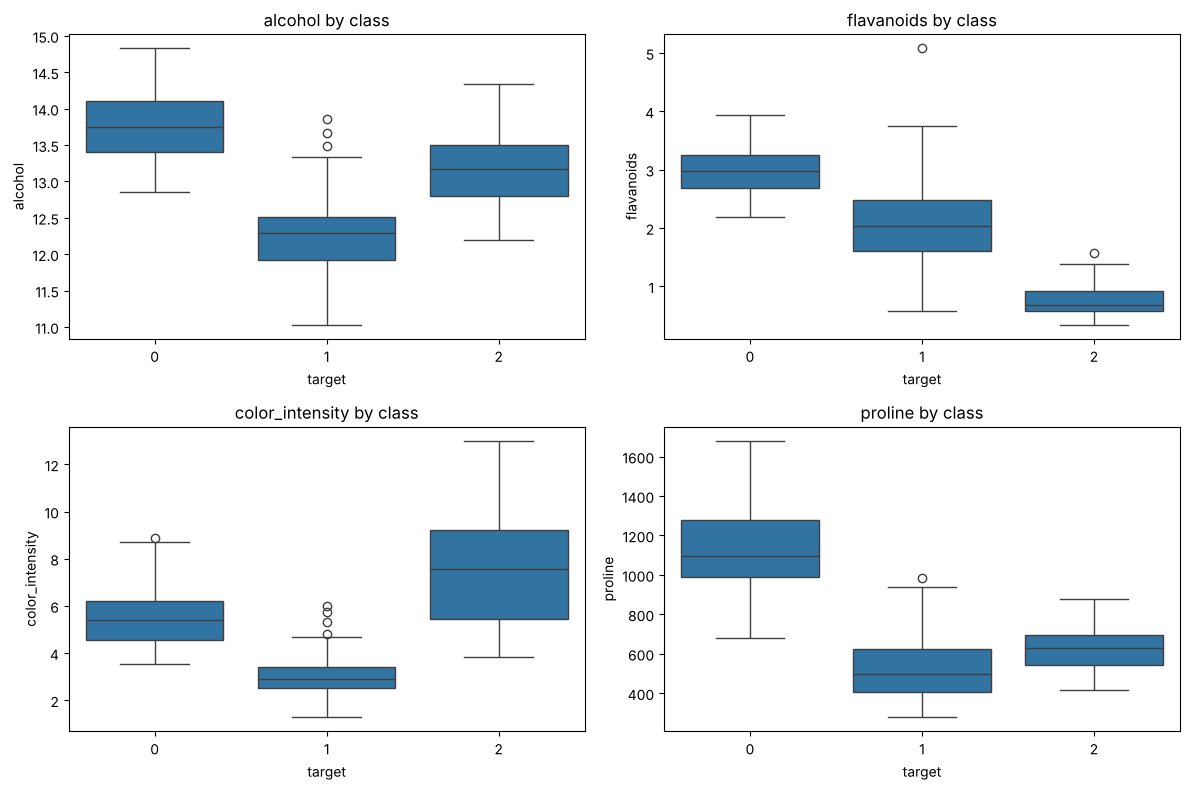

1. Each boxplot shows how one feature is spread out within each wine class.
2. Flavanoids is clearly different across classes: class 0 averages about 2.98 and class 2 only about 0.78.
3. Proline is much higher for class 0 (about 1116) than for class 1 (about 520) and class 2 (about 630).
4. Alcohol overlaps more between the classes, so it separates them less well.


In [3]:
plot_cols = ["alcohol", "flavanoids", "color_intensity", "proline"]

plt.figure(figsize=(12,8))
for i, col in enumerate(plot_cols):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(x=target_col, y=col, data=df)
    plt.title(col + " by class")
plt.tight_layout()
plt.show()

print("1. Each boxplot shows how one feature is spread out within each wine class.")
print("2. Flavanoids is clearly different across classes: class 0 averages about 2.98 and class 2 only about 0.78.")
print("3. Proline is much higher for class 0 (about 1116) than for class 1 (about 520) and class 2 (about 630).")
print("4. Alcohol overlaps more between the classes, so it separates them less well.")

### 3. Scatterplot using two variables

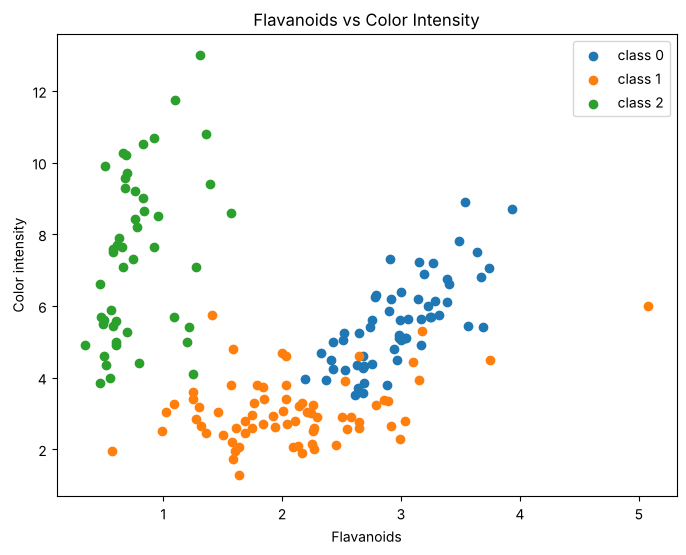

1. The scatterplot uses flavanoids and color intensity, colored by wine class.
2. Class 2 sits on its own at low flavanoids and high color intensity.
3. Class 0 and class 1 overlap a little in the middle, so two variables are not enough to separate them fully.


In [4]:
plt.figure(figsize=(8,6))
for c in [0, 1, 2]:
    subset = df[df[target_col] == c]
    plt.scatter(subset["flavanoids"], subset["color_intensity"], label="class " + str(c))
plt.xlabel("Flavanoids")
plt.ylabel("Color intensity")
plt.title("Flavanoids vs Color Intensity")
plt.legend()
plt.show()

print("1. The scatterplot uses flavanoids and color intensity, colored by wine class.")
print("2. Class 2 sits on its own at low flavanoids and high color intensity.")
print("3. Class 0 and class 1 overlap a little in the middle, so two variables are not enough to separate them fully.")

### 4. Covariance matrix

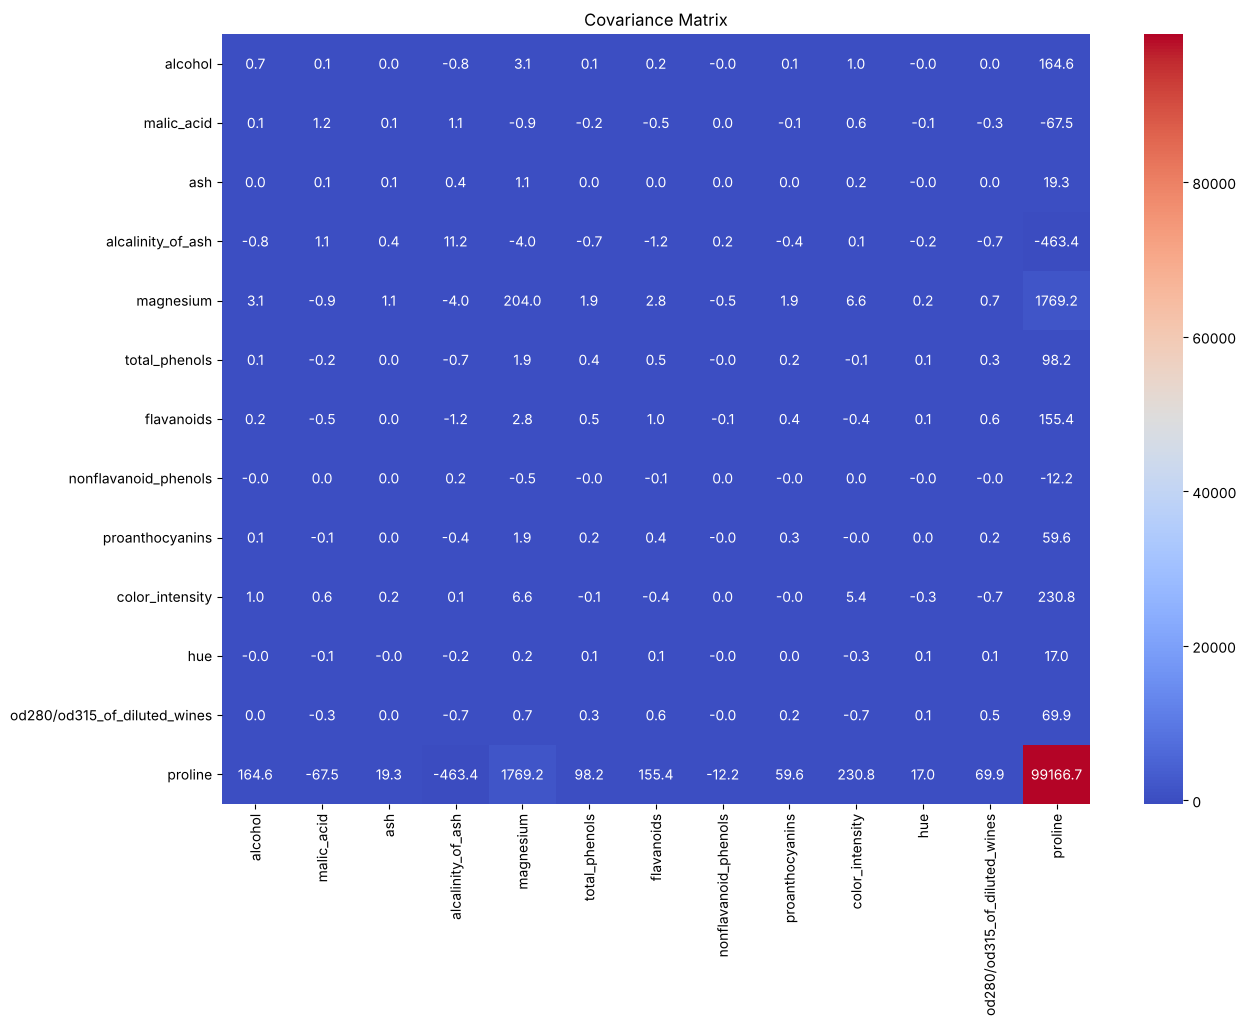

Variance of proline: 99166.7
Variance of hue: 0.052
1. The covariance matrix shows how every pair of features varies together.
2. Proline has a variance of about 99,000, while hue has about 0.05.
3. That is why the heatmap looks flat everywhere except around proline.
4. Features with bigger numbers dominate the covariance, which is a problem for PCA.


In [5]:
cov_matrix = df[features].cov()

plt.figure(figsize=(14,10))
sns.heatmap(cov_matrix, annot=True, fmt=".1f", cmap="coolwarm")
plt.title("Covariance Matrix")
plt.show()

print("Variance of proline:", round(cov_matrix.loc["proline", "proline"], 1))
print("Variance of hue:", round(cov_matrix.loc["hue", "hue"], 3))

print("1. The covariance matrix shows how every pair of features varies together.")
print("2. Proline has a variance of about 99,000, while hue has about 0.05.")
print("3. That is why the heatmap looks flat everywhere except around proline.")
print("4. Features with bigger numbers dominate the covariance, which is a problem for PCA.")

### 5. Data scaling

In [6]:
X = df[features]
y = df[target_col]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

scaled_summary = pd.DataFrame({
    "mean": X_scaled_df.mean().round(3) + 0.0,
    "std": X_scaled_df.std().round(3)
})
print(scaled_summary)

print("1. StandardScaler transforms every feature using z = (x - mean) / std, giving mean 0 and standard deviation 1.")
print("2. The printed means are about 0 and the standard deviations are about 1, which confirms the scaling worked.")
print("3. Now every feature contributes equally, so large-scale features like proline no longer dominate.")
print("4. Scaling is essential before PCA, because PCA picks directions of maximum variance and would otherwise just follow the biggest-scale feature.")

                              mean    std
alcohol                        0.0  1.003
malic_acid                     0.0  1.003
ash                            0.0  1.003
alcalinity_of_ash              0.0  1.003
magnesium                      0.0  1.003
total_phenols                  0.0  1.003
flavanoids                     0.0  1.003
nonflavanoid_phenols           0.0  1.003
proanthocyanins                0.0  1.003
color_intensity                0.0  1.003
hue                            0.0  1.003
od280/od315_of_diluted_wines   0.0  1.003
proline                        0.0  1.003
1. StandardScaler transforms every feature using z = (x - mean) / std, giving mean 0 and standard deviation 1.
2. The printed means are about 0 and the standard deviations are about 1, which confirms the scaling worked.
3. Now every feature contributes equally, so large-scale features like proline no longer dominate.
4. Scaling is essential before PCA, because PCA picks directions of maximum variance and woul

### 6. Better class separation using principal components

Variance explained by each component: [0.362 0.192]
Total variance kept: 0.554


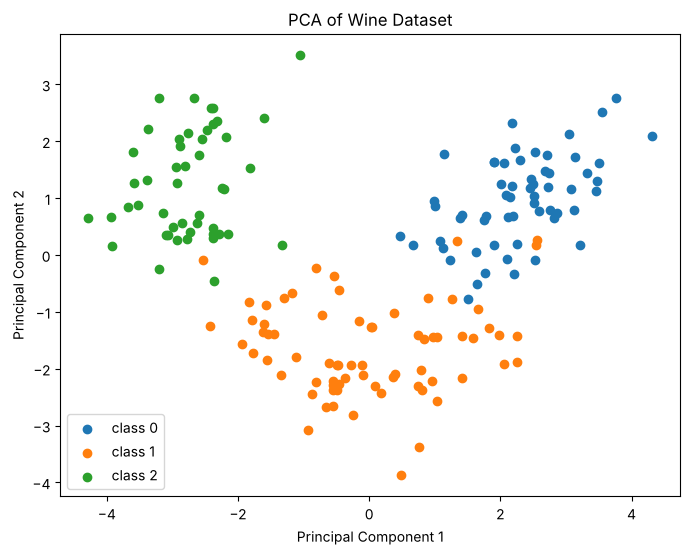

1. PCA combines the 13 scaled features into new components, ordered by how much variance they capture.
2. PC1 captures about 36% of the variance and PC2 about 19%, so the two together keep about 55%.
3. In the PCA plot the three classes form separate groups, with only a few points overlapping.
4. This is cleaner than the flavanoids vs color intensity scatterplot, so the principal components separate the classes better.


In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Variance explained by each component:", pca.explained_variance_ratio_.round(3))
print("Total variance kept:", round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(8,6))
for c in [0, 1, 2]:
    plt.scatter(X_pca[y == c, 0], X_pca[y == c, 1], label="class " + str(c))
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Wine Dataset")
plt.legend()
plt.show()

print("1. PCA combines the 13 scaled features into new components, ordered by how much variance they capture.")
print("2. PC1 captures about 36% of the variance and PC2 about 19%, so the two together keep about 55%.")
print("3. In the PCA plot the three classes form separate groups, with only a few points overlapping.")
print("4. This is cleaner than the flavanoids vs color intensity scatterplot, so the principal components separate the classes better.")

## Conclusion

The features were on very different scales (proline dominated the covariance matrix), so they were scaled with StandardScaler before running PCA. After that, the first two principal components kept about 55% of the variance and separated the three wine classes more clearly than the two-variable scatterplot did.